# 🧠 Epileptic Seizure Prediction
**Dataset:** Physiological signals — Heartbeat, EMG, SpO₂, Blood Pressure  
**Target Classes:** `no epileptic` | `early prediction` | `epileptic`

---
## Cell 1 — Import Libraries

In [1]:
# ─── Standard & Data ───────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# ─── Visualization ─────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
sns.set_theme(style='whitegrid', palette='Set2')
import os
os.makedirs('plots', exist_ok=True)   # all plots saved to ./plots/

# ─── Preprocessing & Splitting ─────────────────────────────────────────────
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# ─── Classifiers ───────────────────────────────────────────────────────────
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# ─── Evaluation ────────────────────────────────────────────────────────────
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# ─── Model Persistence ─────────────────────────────────────────────────────
import pickle

print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


---
## Cell 2 — Read Dataset & Basic DataFrame Info

In [2]:
# ─── Load Dataset ──────────────────────────────────────────────────────────
df = pd.read_csv('epileptic_seizure_prediction_dataset.csv')

print('=' * 55)
print('           DATASET OVERVIEW')
print('=' * 55)
print(f'  Shape        : {df.shape[0]} rows × {df.shape[1]} columns')
print(f'  Features     : {df.shape[1] - 1}')
print(f'  Target col   : target')
print('=' * 55)

print('\n📄 First 5 rows:')
display(df.head())

print('\n📄 Last 5 rows:')
display(df.tail())

print('\n🔢 Data Types & Non-Null Counts:')
df.info()

print('\n📊 Statistical Summary (Numerical Features):')
display(df.describe().round(3))

print('\n🎯 Target Class Distribution:')
display(df['target'].value_counts().rename_axis('Class').reset_index(name='Count'))

print('\n🔍 Missing Values per Column:')
missing = df.isnull().sum()
display(missing[missing > 0] if missing.any() else pd.Series({'No missing values found': 0}))

print('\n🔁 Duplicate Rows:', df.duplicated().sum())

           DATASET OVERVIEW
  Shape        : 5000 rows × 5 columns
  Features     : 4
  Target col   : target

📄 First 5 rows:


,heartbeat,EMG (0-1024),spo2,bp,target
0,73.29,278.60,97.68,105.31,no epileptic
1,129.26,752.66,91.66,175.98,epileptic
2,140.75,751.98,89.55,159.42,epileptic
3,55.86,279.13,97.99,127.43,no epileptic
4,72.77,279.16,97.95,106.76,no epileptic



📄 Last 5 rows:


,heartbeat,EMG (0-1024),spo2,bp,target
4995,107.20,606.44,94.67,122.71,early prediction
4996,85.43,103.63,99.03,127.01,no epileptic
4997,131.11,886.99,89.88,152.06,epileptic
4998,89.45,261.16,92.37,129.30,early prediction
4999,76.16,177.01,98.14,130.71,no epileptic



🔢 Data Types & Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   heartbeat     5000 non-null   float64
 1   EMG (0-1024)  5000 non-null   float64
 2   spo2          5000 non-null   float64
 3   bp            5000 non-null   float64
 4   target        5000 non-null   object 
dtypes: float64(4), object(1)
memory usage: 195.4+ KB

📊 Statistical Summary (Numerical Features):


...


🎯 Target Class Distribution:


,Class,Count
0,no epileptic,1667
1,early prediction,1667
2,epileptic,1666



🔍 Missing Values per Column:


No missing values found    0
dtype: int64


🔁 Duplicate Rows: 0


---
## Cell 3 — EDA: Visualizations

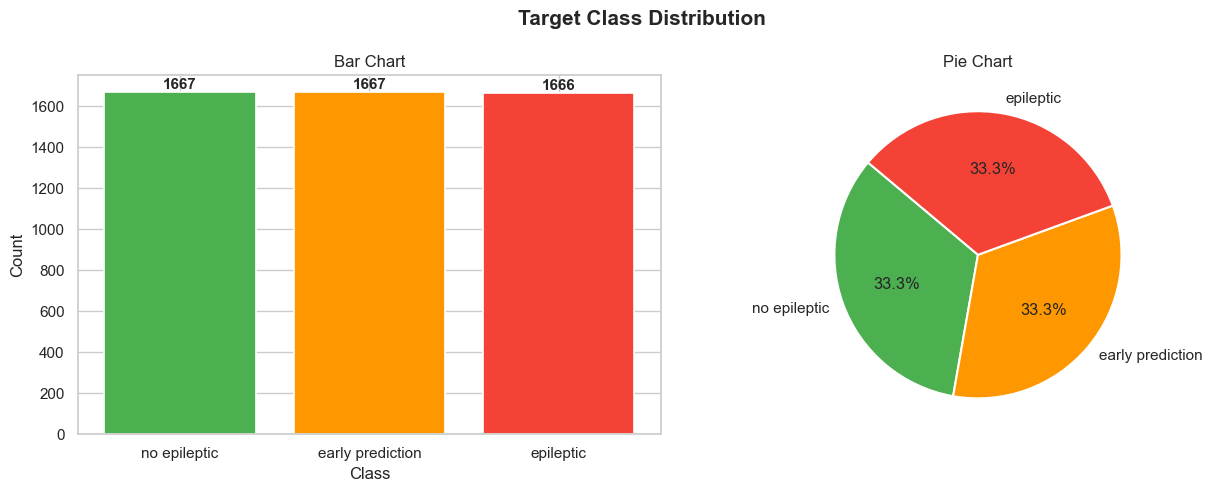

💾 Saved → plots/01_class_distribution.png


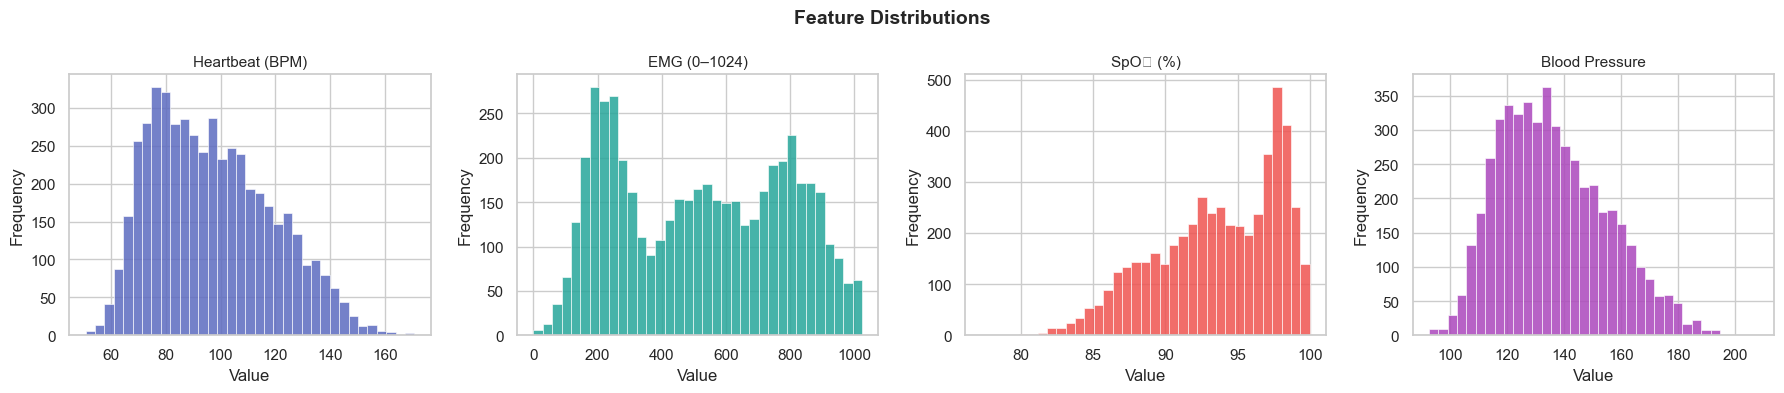

💾 Saved → plots/02_feature_histograms.png


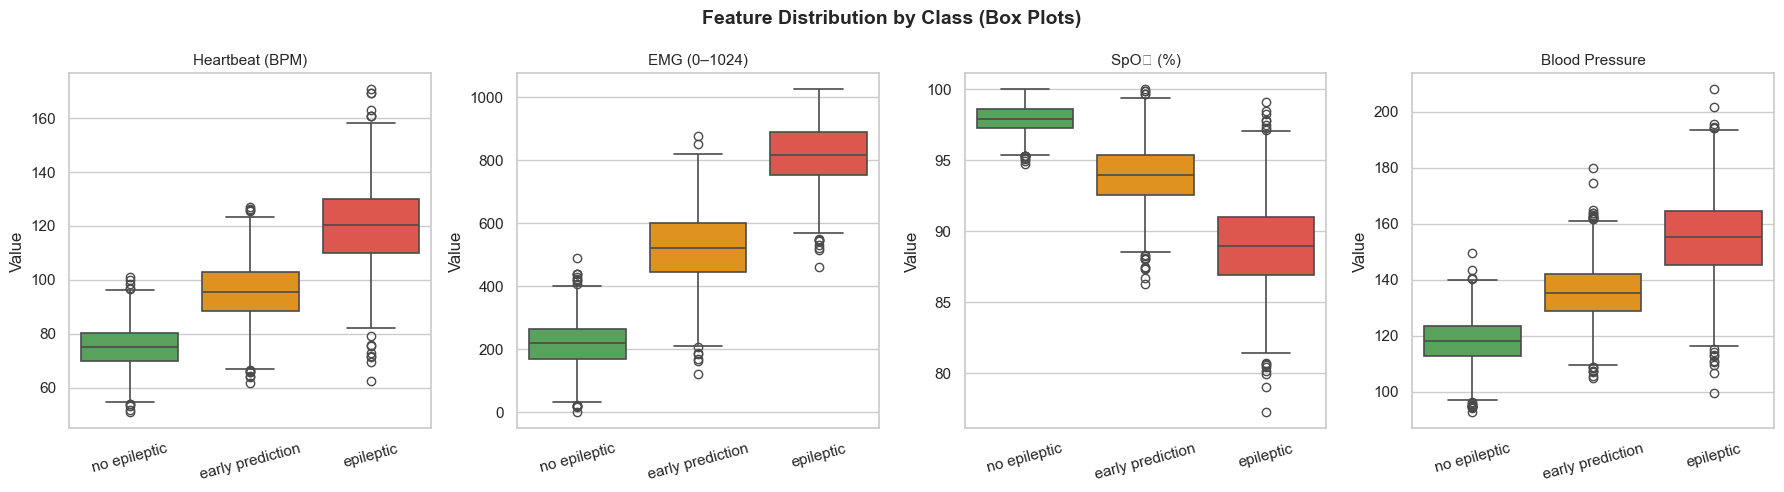

💾 Saved → plots/03_boxplots_by_class.png


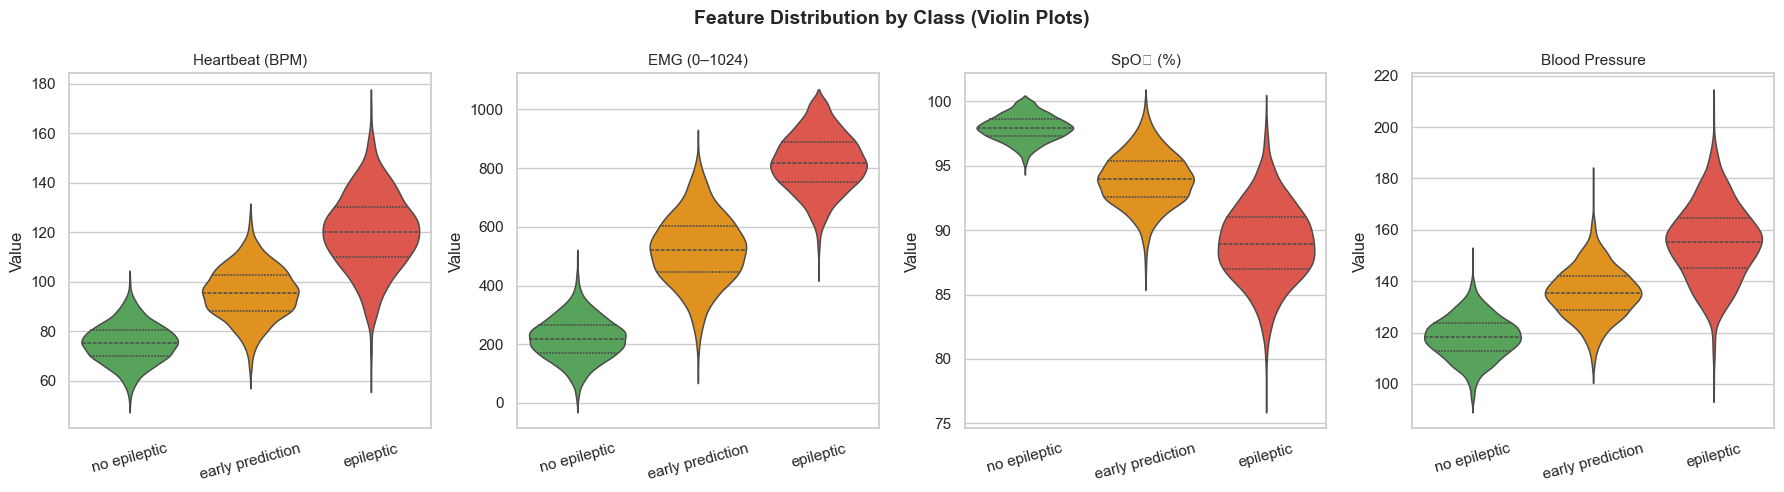

💾 Saved → plots/04_violinplots_by_class.png


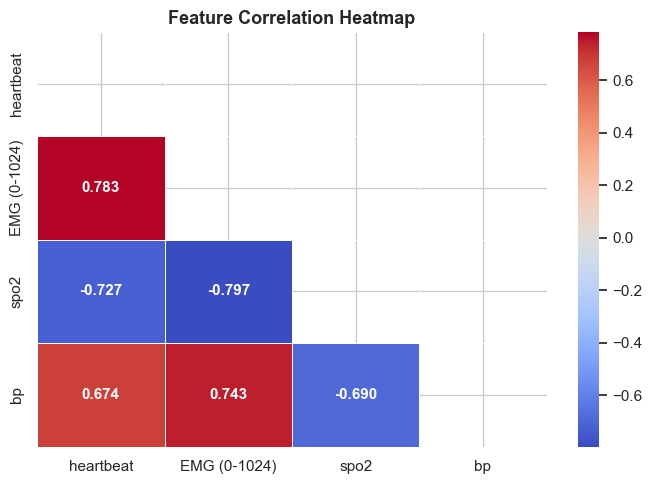

💾 Saved → plots/05_correlation_heatmap.png


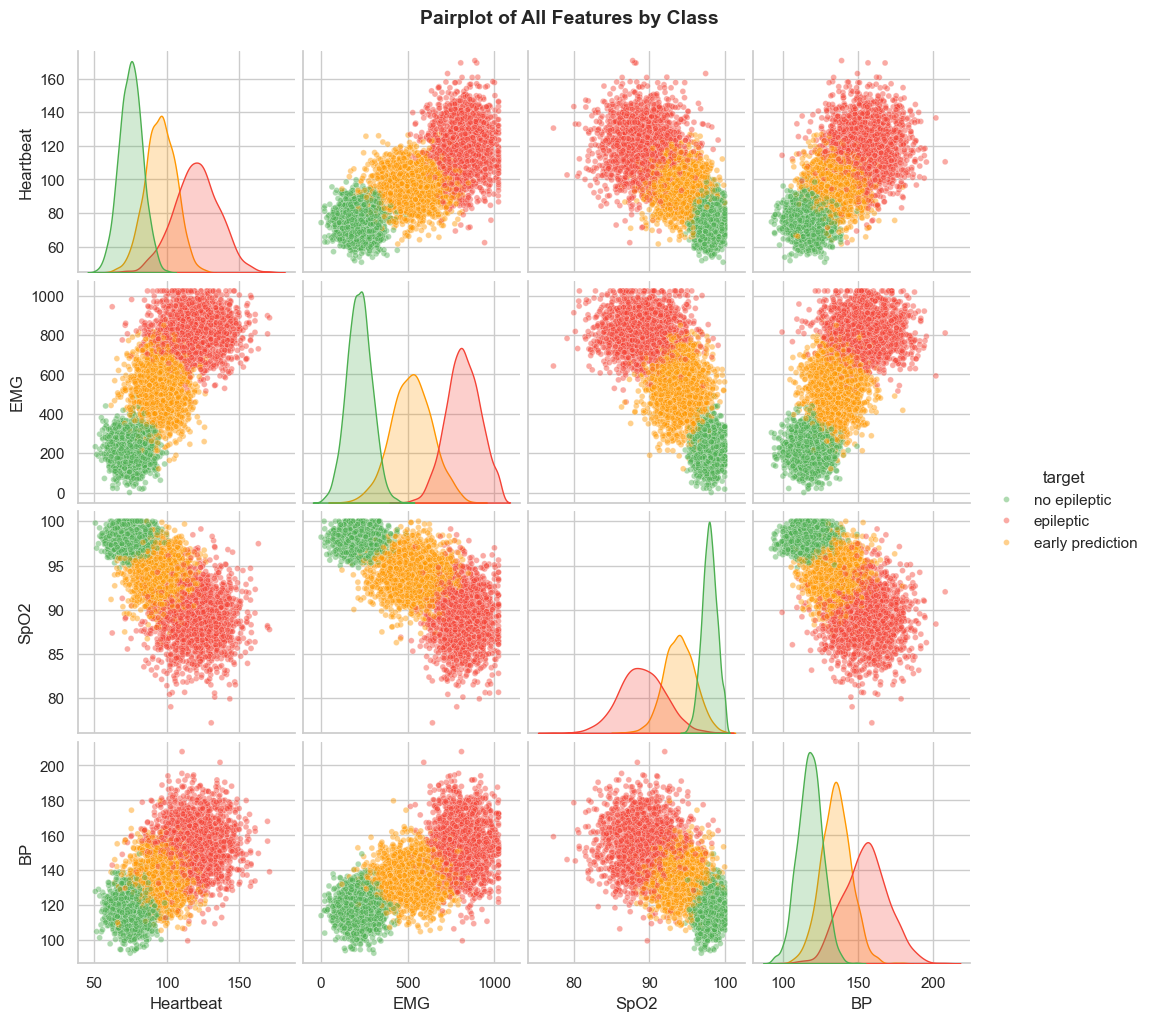

💾 Saved → plots/06_pairplot.png


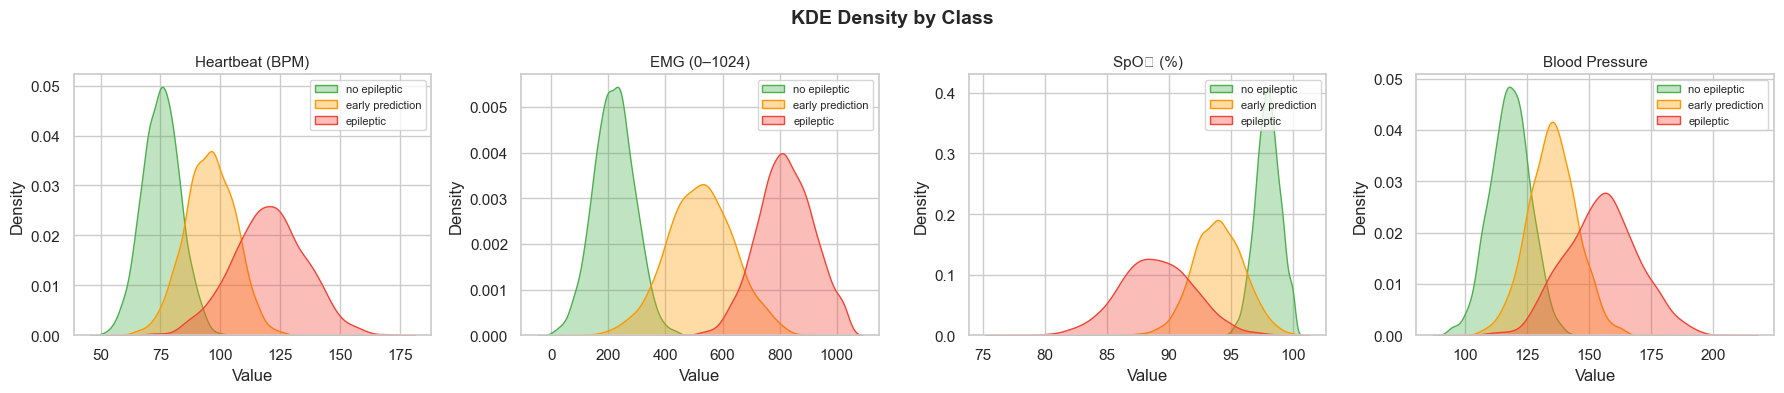

💾 Saved → plots/07_kde_by_class.png

✅ All 7 EDA plots saved in the ./plots/ directory.


In [3]:
features   = ['heartbeat', 'EMG (0-1024)', 'spo2', 'bp']
feat_labels = ['Heartbeat (BPM)', 'EMG (0–1024)', 'SpO₂ (%)', 'Blood Pressure']
class_order = ['no epileptic', 'early prediction', 'epileptic']
palette     = {'no epileptic': '#4CAF50', 'early prediction': '#FF9800', 'epileptic': '#F44336'}

# ── Plot 1 : Target Class Distribution (Count + Pie) ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Target Class Distribution', fontsize=15, fontweight='bold')

counts = df['target'].value_counts().reindex(class_order)
bars = axes[0].bar(counts.index, counts.values,
                   color=[palette[c] for c in counts.index], edgecolor='white', linewidth=1.2)
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
                 str(val), ha='center', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Class', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].set_title('Bar Chart')

axes[1].pie(counts.values, labels=counts.index,
            colors=[palette[c] for c in counts.index],
            autopct='%1.1f%%', startangle=140,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Pie Chart')

plt.tight_layout()
plt.savefig('plots/01_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/01_class_distribution.png')

# ── Plot 2 : Histograms for each feature ──────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle('Feature Distributions', fontsize=14, fontweight='bold')
colors = ['#5C6BC0', '#26A69A', '#EF5350', '#AB47BC']
for ax, feat, label, color in zip(axes, features, feat_labels, colors):
    ax.hist(df[feat], bins=35, color=color, edgecolor='white', linewidth=0.5, alpha=0.85)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')
plt.tight_layout()
plt.savefig('plots/02_feature_histograms.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/02_feature_histograms.png')

# ── Plot 3 : Box Plots by Class ────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle('Feature Distribution by Class (Box Plots)', fontsize=14, fontweight='bold')
for ax, feat, label in zip(axes, features, feat_labels):
    sns.boxplot(data=df, x='target', y=feat, order=class_order,
                palette=palette, ax=ax, linewidth=1.2)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Value')
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig('plots/03_boxplots_by_class.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/03_boxplots_by_class.png')

# ── Plot 4 : Violin Plots by Class ────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle('Feature Distribution by Class (Violin Plots)', fontsize=14, fontweight='bold')
for ax, feat, label in zip(axes, features, feat_labels):
    sns.violinplot(data=df, x='target', y=feat, order=class_order,
                   palette=palette, ax=ax, inner='quartile', linewidth=1.1)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Value')
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig('plots/04_violinplots_by_class.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/04_violinplots_by_class.png')

# ── Plot 5 : Correlation Heatmap ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))
corr = df[features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm',
            mask=mask, ax=ax, linewidths=0.5,
            annot_kws={'size': 11, 'weight': 'bold'})
ax.set_title('Feature Correlation Heatmap', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/05_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/05_correlation_heatmap.png')

# ── Plot 6 : Pairplot ──────────────────────────────────────────────────────
pair_df = df.copy()
pair_df.columns = ['Heartbeat', 'EMG', 'SpO2', 'BP', 'target']
g = sns.pairplot(pair_df, hue='target',
                 palette=palette,
                 plot_kws={'alpha': 0.45, 's': 18},
                 diag_kind='kde')
g.fig.suptitle('Pairplot of All Features by Class', y=1.02, fontsize=14, fontweight='bold')
g.fig.savefig('plots/06_pairplot.png', dpi=120, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/06_pairplot.png')

# ── Plot 7 : KDE Plots per feature ────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle('KDE Density by Class', fontsize=14, fontweight='bold')
for ax, feat, label in zip(axes, features, feat_labels):
    for cls in class_order:
        sns.kdeplot(df[df['target'] == cls][feat],
                    ax=ax, fill=True, alpha=0.35,
                    color=palette[cls], label=cls)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel('Value')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('plots/07_kde_by_class.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/07_kde_by_class.png')

print('\n✅ All 7 EDA plots saved in the ./plots/ directory.')

---
## Cell 4 — Data Preprocessing & Train/Test Split (80:20)

In [4]:
# ─── Encode Target ─────────────────────────────────────────────────────────
le = LabelEncoder()
df['target_enc'] = le.fit_transform(df['target'])

print('Label Encoding Map:')
for orig, enc in zip(le.classes_, le.transform(le.classes_)):
    print(f'  {enc}  →  {orig}')

# ─── Feature Matrix & Target Vector ────────────────────────────────────────
X = df[features].values
y = df['target_enc'].values

# ─── Feature Scaling ───────────────────────────────────────────────────────
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ─── Split 80 : 20 ─────────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)

print('\n' + '=' * 45)
print('          TRAIN / TEST SPLIT')
print('=' * 45)
print(f'  Total samples  : {len(y)}')
print(f'  Train samples  : {len(y_train)}  ({len(y_train)/len(y)*100:.0f}%)')
print(f'  Test  samples  : {len(y_test)}   ({len(y_test)/len(y)*100:.0f}%)')
print(f'  Features       : {X_train.shape[1]}')
print('=' * 45)

print('\nTrain class distribution:')
unique, counts_arr = np.unique(y_train, return_counts=True)
for u, c in zip(unique, counts_arr):
    print(f'  {le.inverse_transform([u])[0]:18s} → {c}')

print('\nTest class distribution:')
unique, counts_arr = np.unique(y_test, return_counts=True)
for u, c in zip(unique, counts_arr):
    print(f'  {le.inverse_transform([u])[0]:18s} → {c}')

Label Encoding Map:
  0  →  early prediction
  1  →  epileptic
  2  →  no epileptic

          TRAIN / TEST SPLIT
  Total samples  : 5000
  Train samples  : 4000  (80%)
  Test  samples  : 1000   (20%)
  Features       : 4

Train class distribution:
  early prediction   → 1333
  epileptic          → 1333
  no epileptic       → 1334

Test class distribution:
  early prediction   → 334
  epileptic          → 333
  no epileptic       → 333


---
## Cell 5a — Classifier 1: Random Forest

   RANDOM FOREST CLASSIFIER — RESULTS
  Accuracy : 98.50%

Classification Report:
                  precision    recall  f1-score   support

early prediction       0.99      0.97      0.98       334
       epileptic       0.97      0.99      0.98       333
    no epileptic       0.99      1.00      1.00       333

        accuracy                           0.98      1000
       macro avg       0.99      0.99      0.98      1000
    weighted avg       0.99      0.98      0.98      1000



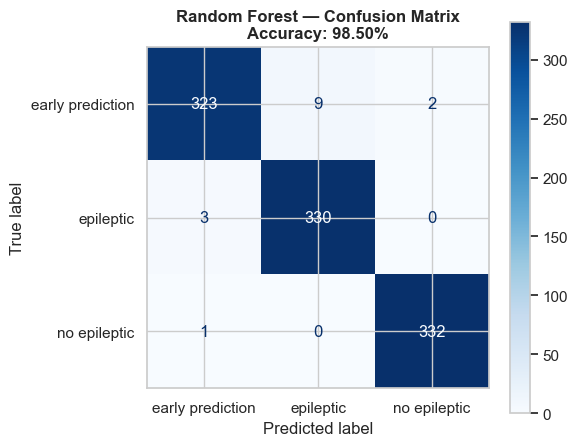

💾 Saved → plots/08_rf_confusion_matrix.png


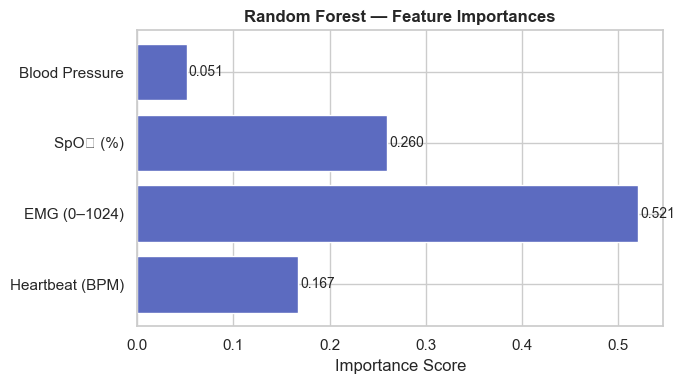

💾 Saved → plots/09_rf_feature_importance.png


In [5]:
# ─── Random Forest Classifier ──────────────────────────────────────────────
rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

rf_pred   = rf_model.predict(X_test)
rf_acc    = accuracy_score(y_test, rf_pred)

print('=' * 50)
print('   RANDOM FOREST CLASSIFIER — RESULTS')
print('=' * 50)
print(f'  Accuracy : {rf_acc*100:.2f}%')
print('=' * 50)
print('\nClassification Report:')
print(classification_report(y_test, rf_pred, target_names=le.classes_))

# ─── Confusion Matrix ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred,
    display_labels=le.classes_,
    cmap='Blues', ax=ax
)
ax.set_title(f'Random Forest — Confusion Matrix\nAccuracy: {rf_acc*100:.2f}%',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/08_rf_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/08_rf_confusion_matrix.png')

# ─── Feature Importance ────────────────────────────────────────────────────
importances = rf_model.feature_importances_
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(feat_labels, importances, color='#5C6BC0', edgecolor='white')
ax.set_xlabel('Importance Score')
ax.set_title('Random Forest — Feature Importances', fontsize=12, fontweight='bold')
for i, v in enumerate(importances):
    ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=10)
plt.tight_layout()
plt.savefig('plots/09_rf_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/09_rf_feature_importance.png')

---
## Cell 5b — Classifier 2: Support Vector Machine (SVM)

   SVM (RBF Kernel) CLASSIFIER — RESULTS
  Accuracy : 98.70%

Classification Report:
                  precision    recall  f1-score   support

early prediction       0.99      0.97      0.98       334
       epileptic       0.98      0.99      0.98       333
    no epileptic       0.99      1.00      1.00       333

        accuracy                           0.99      1000
       macro avg       0.99      0.99      0.99      1000
    weighted avg       0.99      0.99      0.99      1000



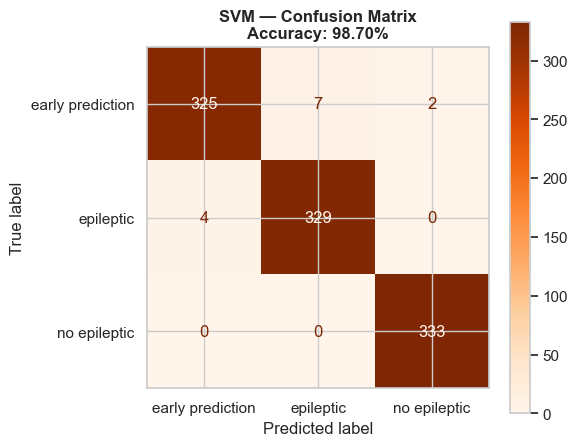

💾 Saved → plots/10_svm_confusion_matrix.png


In [6]:
# ─── SVM Classifier ────────────────────────────────────────────────────────
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_model.fit(X_train, y_train)

svm_pred  = svm_model.predict(X_test)
svm_acc   = accuracy_score(y_test, svm_pred)

print('=' * 50)
print('   SVM (RBF Kernel) CLASSIFIER — RESULTS')
print('=' * 50)
print(f'  Accuracy : {svm_acc*100:.2f}%')
print('=' * 50)
print('\nClassification Report:')
print(classification_report(y_test, svm_pred, target_names=le.classes_))

# ─── Confusion Matrix ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred,
    display_labels=le.classes_,
    cmap='Oranges', ax=ax
)
ax.set_title(f'SVM — Confusion Matrix\nAccuracy: {svm_acc*100:.2f}%',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/10_svm_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/10_svm_confusion_matrix.png')

---
## Cell 5c — Classifier 3: K-Nearest Neighbors (KNN)

   KNN CLASSIFIER — RESULTS
  Accuracy : 98.10%

Classification Report:
                  precision    recall  f1-score   support

early prediction       0.98      0.97      0.97       334
       epileptic       0.98      0.98      0.98       333
    no epileptic       0.99      1.00      0.99       333

        accuracy                           0.98      1000
       macro avg       0.98      0.98      0.98      1000
    weighted avg       0.98      0.98      0.98      1000



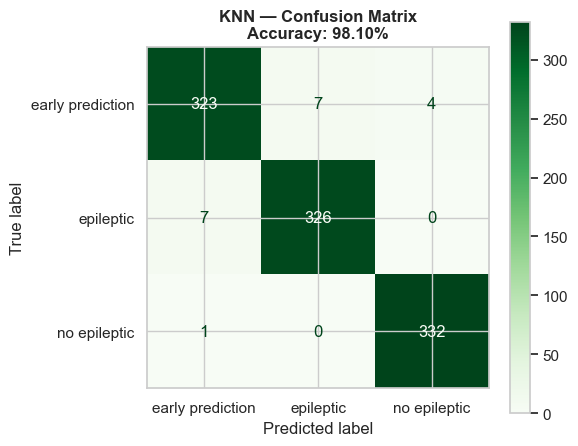

💾 Saved → plots/11_knn_confusion_matrix.png


In [7]:
# ─── KNN Classifier ────────────────────────────────────────────────────────
knn_model = KNeighborsClassifier(n_neighbors=7, metric='minkowski', weights='distance')
knn_model.fit(X_train, y_train)

knn_pred  = knn_model.predict(X_test)
knn_acc   = accuracy_score(y_test, knn_pred)

print('=' * 50)
print('   KNN CLASSIFIER — RESULTS')
print('=' * 50)
print(f'  Accuracy : {knn_acc*100:.2f}%')
print('=' * 50)
print('\nClassification Report:')
print(classification_report(y_test, knn_pred, target_names=le.classes_))

# ─── Confusion Matrix ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred,
    display_labels=le.classes_,
    cmap='Greens', ax=ax
)
ax.set_title(f'KNN — Confusion Matrix\nAccuracy: {knn_acc*100:.2f}%',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/11_knn_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/11_knn_confusion_matrix.png')

---
## Cell 6 — Compare Accuracy & Save Best Model as `best.pkl`

         MODEL ACCURACY COMPARISON
  Classifier                Accuracy
----------------------------------------------------
  SVM (RBF)                   98.70%
  Random Forest               98.50%
  KNN                         98.10%


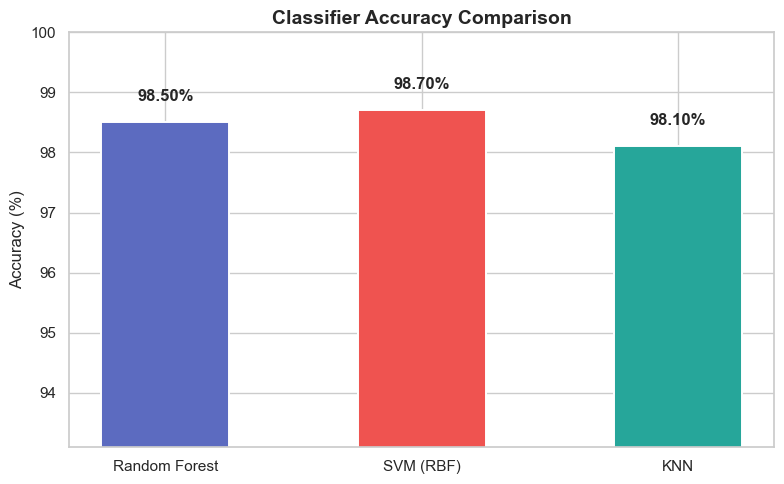

💾 Saved → plots/12_accuracy_comparison.png

🏆  Best Model  : SVM (RBF)
    Accuracy   : 98.70%

✅  Saved best model bundle → best.pkl
    Contains: model, scaler, label_encoder, feature list, model_name, accuracy


In [8]:
# ─── Accuracy Comparison ───────────────────────────────────────────────────
results = {
    'Random Forest': {'model': rf_model,  'accuracy': rf_acc},
    'SVM (RBF)':     {'model': svm_model, 'accuracy': svm_acc},
    'KNN':           {'model': knn_model, 'accuracy': knn_acc},
}

print('=' * 52)
print('         MODEL ACCURACY COMPARISON')
print('=' * 52)
print(f'  {"Classifier":<22}  {"Accuracy":>10}')
print('-' * 52)
for name, info in sorted(results.items(), key=lambda x: -x[1]['accuracy']):
    print(f'  {name:<22}  {info["accuracy"]*100:>9.2f}%')
print('=' * 52)

# ─── Bar Chart Comparison ──────────────────────────────────────────────────
names    = list(results.keys())
accs     = [results[n]['accuracy'] * 100 for n in names]
bar_cols = ['#5C6BC0', '#EF5350', '#26A69A']

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(names, accs, color=bar_cols, edgecolor='white',
              linewidth=1.4, width=0.5)
ax.set_ylim(min(accs) - 5, 100)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Classifier Accuracy Comparison', fontsize=14, fontweight='bold')
for bar, val in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/12_accuracy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → plots/12_accuracy_comparison.png')

# ─── Select Best Model ─────────────────────────────────────────────────────
best_name = max(results, key=lambda n: results[n]['accuracy'])
best_model = results[best_name]['model']
best_acc   = results[best_name]['accuracy']

print(f'\n🏆  Best Model  : {best_name}')
print(f'    Accuracy   : {best_acc*100:.2f}%')

# ─── Save as best.pkl ──────────────────────────────────────────────────────
bundle = {
    'model':        best_model,
    'scaler':       scaler,
    'label_encoder': le,
    'features':     features,
    'model_name':   best_name,
    'accuracy':     best_acc,
}
with open('best.pkl', 'wb') as f:
    pickle.dump(bundle, f)

print(f'\n✅  Saved best model bundle → best.pkl')
print('    Contains: model, scaler, label_encoder, feature list, model_name, accuracy')

---
## Cell 7 — Standalone Testing Cell (Load `best.pkl` & Predict from User Input)

In [9]:
# ══════════════════════════════════════════════════════════════════
#   STANDALONE TEST CELL — run independently anytime
#   Loads best.pkl, takes user input, and predicts seizure class
# ══════════════════════════════════════════════════════════════════
import pickle
import numpy as np

# ─── Load saved bundle ────────────────────────────────────────────
with open('best.pkl', 'rb') as f:
    bundle = pickle.load(f)

model        = bundle['model']
scaler       = bundle['scaler']
le           = bundle['label_encoder']
feat_names   = bundle['features']
model_name   = bundle['model_name']
model_acc    = bundle['accuracy']

print('=' * 55)
print('   🧠 EPILEPTIC SEIZURE PREDICTION — TEST')
print('=' * 55)
print(f'   Loaded model : {model_name}')
print(f'   Test accuracy: {model_acc*100:.2f}%')
print('=' * 55)
print('\n📌 Reference Ranges (from training data):')
print('   Heartbeat    :  50  – 171  BPM')
print('   EMG          :   0  – 1024')
print('   SpO₂         :  77  – 100  %')
print('   Blood Pressure:  93  – 208  mmHg')
print()

# ─── Collect User Input ───────────────────────────────────────────
try:
    heartbeat = float(input('Enter Heartbeat (BPM)       : '))
    emg       = float(input('Enter EMG value (0–1024)    : '))
    spo2      = float(input('Enter SpO₂ (%)              : '))
    bp        = float(input('Enter Blood Pressure (mmHg) : '))
except ValueError:
    print('⚠️  Invalid input. Please enter numeric values.')
    raise

# ─── Preprocess & Predict ─────────────────────────────────────────
input_arr   = np.array([[heartbeat, emg, spo2, bp]])
input_scaled = scaler.transform(input_arr)

pred_enc    = model.predict(input_scaled)[0]
pred_label  = le.inverse_transform([pred_enc])[0]

# ─── Confidence (if model supports predict_proba) ─────────────────
if hasattr(model, 'predict_proba'):
    probas = model.predict_proba(input_scaled)[0]
    conf   = probas[pred_enc] * 100
    conf_info = f'  Confidence   : {conf:.1f}%'
else:
    conf_info = '  (Confidence not available for this model)'

# ─── Display Result ───────────────────────────────────────────────
emoji_map = {
    'no epileptic':      '🟢  LOW RISK',
    'early prediction':  '🟡  EARLY WARNING',
    'epileptic':         '🔴  HIGH RISK — SEEK MEDICAL ATTENTION'
}

print('\n' + '=' * 55)
print('   PREDICTION RESULT')
print('=' * 55)
print(f'  Input        : heartbeat={heartbeat}, EMG={emg}, SpO₂={spo2}, BP={bp}')
print(f'  Predicted    : {pred_label}')
print(f'  Status       : {emoji_map.get(pred_label, pred_label)}')
print(conf_info)
print('=' * 55)

   🧠 EPILEPTIC SEIZURE PREDICTION — TEST
   Loaded model : SVM (RBF)
   Test accuracy: 98.70%

📌 Reference Ranges (from training data):
   Heartbeat    :  50  – 171  BPM
   EMG          :   0  – 1024
   SpO₂         :  77  – 100  %
   Blood Pressure:  93  – 208  mmHg



Enter Heartbeat (BPM)       :  78
Enter EMG value (0–1024)    :  344
Enter SpO₂ (%)              :  97
Enter Blood Pressure (mmHg) :  56



   PREDICTION RESULT
  Input        : heartbeat=78.0, EMG=344.0, SpO₂=97.0, BP=56.0
  Predicted    : epileptic
  Status       : 🔴  HIGH RISK — SEEK MEDICAL ATTENTION
  (Confidence not available for this model)
